# Pandas: Ereignisse, Ergebnisräume und Simulation
### Unterrichtsmaterial | Julia Brutskaya

---
**Kontext:** Wahrscheinlichkeitsrechnung, Tag 1 – Datenwald-Akademie<br>
**Bibliotheken:** `pandas`, `numpy`, `matplotlib`

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="130"> <img src="png%20Dateien/etta_elster.png" alt="Etta" width="130"> <img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="130"> <img src="png%20Dateien/der_ausreisser.png" alt="Der Ausreißer" width="130">

Früher hast du Ereignisse, Baumdiagramme und das Gesetz der großen Zahlen mit Stift und Papier kennengelernt. Herr Bauchgefühl hatte zu allem eine Meinung. Jetzt prüfen wir seine Behauptungen mit Pandas, und zwar nicht 10-mal, sondern 10 000-mal.

Dabei lernst du neue Pandas-Werkzeuge kennen:

| Block | Inhalt | Neu in Pandas |
|---|---|---|
| A | Ereignisse sind Masken | `&`, `\|`, `~`, `isin`, `between`, `query` |
| B | Der Ergebnisraum als Tabelle | `merge(how="cross")`, `sum(axis=1)` |
| C | Ziehen simulieren | `sample` mit `replace=True` und `weights` |
| D | Das Gesetz der großen Zahlen | `expanding()` |
| E | „Mindestens einmal" | `any` / `all` mit `axis=1` |
| F | Der Serien-Detektor und weitere Übungen | `shift()` + `cumsum()` |

---
# Block A – Ereignisse sind Masken

## 1 – Die Kurs-Umfrage laden

Dieselbe Umfrage wie in der Statistik-Woche. Wir losen gedanklich **eine Person zufällig aus**. Jede der 20 Personen hat dieselbe Chance, das ist ein Laplace-Experiment.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

zeilen = [
    # teilnehmer_id, kurszeit, getraenk, tshirt, haustiere, anfahrt_min, lernstunden, punkte
    (101, "Vormittag", "Kaffee", "M", 0, 25, 3, 50), (102, "Abend", "Tee", "S", 1, 35, 4, 58),
    (103, "Vormittag", "Mate", "L", 0, 18, 4, 63), (104, "Vormittag", "Kaffee", "L", 2, 42, 9, 81),
    (105, "Abend", "Wasser", "M", 0, 30, 8, 84), (106, "Vormittag", "Tee", "M", 1, 28, 5, 60),
    (107, "Abend", "Kaffee", "XL", 0, 55, 9, 86), (108, "Vormittag", "Kaffee", "S", 3, 12, 7, 79),
    (109, "Vormittag", "Mate", "M", 1, 38, 3, 57), (110, "Abend", "Tee", "M", 0, 115, 12, 66),
    (111, "Vormittag", "Kaffee", "L", 0, 32, 10, 88), (112, "Abend", "Mate", "L", 2, 45, 1, 47),
    (113, "Vormittag", "Wasser", "S", 1, 22, 6, 72), (114, "Vormittag", "Kaffee", "M", 0, 35, 5, 62),
    (115, "Abend", "Tee", "L", 1, 48, 11, 94), (116, "Vormittag", "Tee", "M", 0, 30, 8, 76),
    (117, "Abend", "Kaffee", "M", 3, 65, 2, 52), (118, "Vormittag", "Mate", "XL", 1, 40, 6, 69),
    (119, "Abend", "Wasser", "S", 0, 52, 7, 70), (120, "Vormittag", "Kaffee", "L", 2, 25, 6, 61),
]
spalten = ["teilnehmer_id", "kurszeit", "getraenk", "tshirt", "haustiere",
           "anfahrt_min", "lernstunden", "punkte"]
umfrage = pd.DataFrame(zeilen, columns=spalten)

BLAU, ORANGE = "#2a78d6", "#eb6834"
umfrage.head()

,teilnehmer_id,kurszeit,getraenk,tshirt,haustiere,anfahrt_min,lernstunden,punkte
0,101,Vormittag,Kaffee,M,0,25,3,50
1,102,Abend,Tee,S,1,35,4,58
2,103,Vormittag,Mate,L,0,18,4,63
3,104,Vormittag,Kaffee,L,2,42,9,81
4,105,Abend,Wasser,M,0,30,8,84


## 2 – Ein Ereignis ist eine True/False-Spalte

Das Ereignis „die ausgeloste Person trinkt Kaffee" ist eine Spalte mit `True` und `False`, eine **Maske**. Der Mittelwert einer Maske ist der Anteil der `True`-Werte, das kennst du seit Statistik Tag 1. Beim Auslosen einer Person ist das genau die Laplace-Wahrscheinlichkeit |A| / |Ω|.

In [36]:
kaffee = umfrage["getraenk"] == "Kaffee"
abend = umfrage["kurszeit"] == "Abend"

print("P(Kaffee):", kaffee.mean())
print("P(Abend): ", abend.mean())

P(Kaffee): 0.4
P(Abend):  0.4


Ereignisse verknüpfst du mit drei Zeichen:

| Wort | Mengenzeichen | Pandas |
|---|---|---|
| und | A ∩ B | `a & b` |
| oder (inklusiv) | A ∪ B | `a \| b` |
| nicht | Ā | `~a` |

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="120">

> **Herr Bauchgefühl:** „Den Gutschein bekommt, wer Kaffee trinkt oder abends kommt. Das sind 40 % plus 40 %, also 80 %."

In [37]:
print("P(Kaffee und Abend):  ", (kaffee & abend).mean())
print("P(Kaffee oder Abend): ", (kaffee | abend).mean())
print("P(kein Kaffee):       ", (~kaffee).mean())
print()

# Gegenprobe mit dem Additionssatz: P(A ∪ B) = P(A) + P(B) − P(A ∩ B)
print("Additionssatz:", round(kaffee.mean() + abend.mean() - (kaffee & abend).mean(), 2))e
print("Bauchgefühl:  ", kaffee.mean() + abend.mean())

SyntaxError: invalid syntax (1266213880.py, line 7)

<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="120">

Es sind 70 %, nicht 80 %. Die zwei Personen, die abends Kaffee trinken, hat Herr Bauchgefühl doppelt gezählt.

## 3 – Bequemer: `isin`, `between`, `query`

In [ ]:
# isin: eines von mehreren Getränken
print("P(Tee oder Mate):         ", umfrage["getraenk"].isin(["Tee", "Mate"]).mean())

# between: Wertebereich, beide Grenzen gehören dazu
print("P(Anfahrt 20 bis 40 Min.):", umfrage["anfahrt_min"].between(20, 40).mean())

# query: die Bedingung als lesbarer Text, hier mit den Wörtern and / or
gutschein = umfrage.query('getraenk == "Kaffee" or kurszeit == "Abend"')
print("P(Gutschein) mit query:   ", len(gutschein) / len(umfrage))
print()
print(umfrage.query("anfahrt_min > 50")[["teilnehmer_id", "anfahrt_min"]])

P(Tee oder Mate):          0.45
P(Anfahrt 20 bis 40 Min.): 0.55
P(Gutschein) mit query:    0.7

    teilnehmer_id  anfahrt_min
6             107           55
9             110          115
16            117           65
18            119           52


> **Stolperstein Klammern:** Außerhalb von `query` brauchst du `&`, `|` und **Klammern** um jede Bedingung. Ohne Klammern rechnet Python `&` zuerst und es gibt einen Fehler. Und `and` / `or` gehen auf einer ganzen Spalte gar nicht.

In [ ]:
try:
    umfrage["getraenk"] == "Kaffee" & umfrage["kurszeit"] == "Abend"
except TypeError as fehler:
    print("Ohne Klammern:", type(fehler).__name__)

try:
    (umfrage["getraenk"] == "Kaffee") and (umfrage["kurszeit"] == "Abend")
except ValueError as fehler:
    print("Mit and:      ", type(fehler).__name__, "-", str(fehler)[:45], "...")

print("Richtig:      ", ((umfrage["getraenk"] == "Kaffee") & (umfrage["kurszeit"] == "Abend")).sum(), "Personen")

Ohne Klammern: TypeError
Mit and:       ValueError - The truth value of a Series is ambiguous. Use ...
Richtig:       2 Personen


### Übung 1

Übung 9 vom Vormittag. Eine Person wird ausgelost. T: Sie trinkt Tee. A: Sie kommt abends.

- **a)** Berechne P(T), P(A) und P(T ∩ A) mit Masken.
- **b)** Berechne P(T ∪ A) mit einer Maske und prüfe mit dem Additionssatz.
- **c)** Wie groß ist die Wahrscheinlichkeit, dass **nicht** beides zutrifft?
- **d)** Berechne P(T ∪ A) noch einmal mit `query`.

In [ ]:
# a)
tee = umfrage["getraenk"] == "Tee"
abend = umfrage["kurszeit"] == "Abend"
print("P(T)", tee.mean())
print("P(A)", abend.mean())
print("P(T ∩ A)", (tee & abend).mean())

P(T) 0.25
P(A) 0.4
P(T ∩ A) 0.15


In [ ]:
# b)
print("P(T ∪ A)", (tee | abend).mean())
print("Additionssatz", tee.mean() + abend.mean() - (tee & abend).mean())

P(T ∪ A) 0.5
Additionssatz 0.5


In [ ]:
# c) 0,85 = 1 - 0.15 P(T ∩ A)
print("P(nicht beides gleichzeitig)", (~(tee & abend)).mean())

P(nicht beides gleichzeitig) 0.85


In [ ]:
# d)
print("P(T ∪ A) mit query", len(umfrage.query("getraenk == 'Tee' or kurszeit == 'Abend'")) / len(umfrage))

P(T ∪ A) mit query 0.5


---
# Block B – Der Ergebnisraum als Tabelle

## 4 – Zwei Würfel mit `merge(how="cross")`

Bei zwei Würfeln (rot und blau) besteht der Ergebnisraum aus allen Paaren. `merge(how="cross")` kombiniert **jede Zeile links mit jeder Zeile rechts**, ganz ohne Schlüssel.

> **Herr Bauchgefühl:** „Es gibt 11 mögliche Augensummen, von 2 bis 12. Also hat jede die Wahrscheinlichkeit 1/11."

In [ ]:
rot = pd.DataFrame({"rot": range(1, 7)})
blau = pd.DataFrame({"blau": range(1, 7)})

wuerfel = rot.merge(blau, how="cross")
wuerfel["summe"] = wuerfel["rot"] + wuerfel["blau"]

print("Anzahl Ergebnisse:", len(wuerfel))
wuerfel.head(8)

Anzahl Ergebnisse: 36


,rot,blau,summe
0,1,1,2
1,1,2,3
2,1,3,4
3,1,4,5
4,1,5,6
5,1,6,7
6,2,1,3
7,2,2,4


[1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]
P(Summe 7): 0.167
P(Summe 2): 0.028


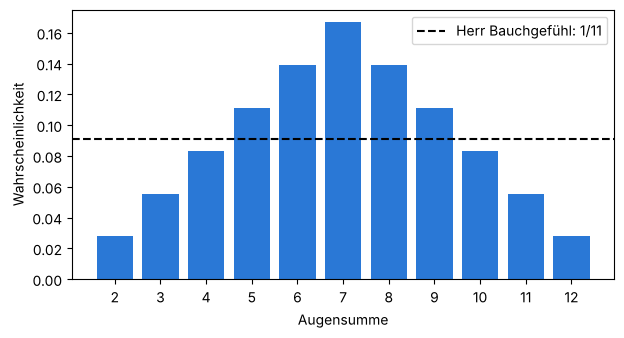

In [ ]:
haeufigkeit = wuerfel["summe"].value_counts().sort_index()
print(haeufigkeit.tolist())
print("P(Summe 7):", round((wuerfel["summe"] == 7).mean(), 3))
print("P(Summe 2):", round((wuerfel["summe"] == 2).mean(), 3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(haeufigkeit.index, haeufigkeit.values / 36, color=BLAU)
ax.axhline(1 / 11, color="black", linestyle="--", label="Herr Bauchgefühl: 1/11")
ax.set_xticks(range(2, 13))
ax.set_xlabel("Augensumme")
ax.set_ylabel("Wahrscheinlichkeit")
ax.legend()
plt.show()

Die 11 Summen sind **nicht** gleich wahrscheinlich: Für die 7 gibt es 6 Wege, für die 2 nur einen. Laplace gilt für die 36 Paare, nicht für die 11 Summen.

## 5 – Zeilenweise rechnen mit `axis=1`

Zwei Münzen: Wie viele Köpfe liegen oben? `(muenzen == "K")` prüft jede Zelle, `.sum(axis=1)` zählt **pro Zeile** quer über die Spalten.

In [ ]:
muenzen = pd.DataFrame({"rot": ["K", "Z"]}).merge(pd.DataFrame({"blau": ["K", "Z"]}), how="cross")
muenzen["anzahl_kopf"] = (muenzen[["rot", "blau"]] == "K").sum(axis=1)
print(muenzen)
print()
print(muenzen["anzahl_kopf"].value_counts(normalize=True).sort_index())

  rot blau  anzahl_kopf
0   K    K            2
1   K    Z            1
2   Z    K            1
3   Z    Z            0

anzahl_kopf
0    0.25
1    0.50
2    0.25
Name: proportion, dtype: float64


`axis=0` (Standard) rechnet **nach unten** pro Spalte, `axis=1` rechnet **quer** pro Zeile. Herr Bauchgefühls „je ein Drittel" für 0, 1 oder 2 Köpfe stimmt also nicht: Genau ein Kopf hat zwei Wege (KZ und ZK).

### Übung 2

Übung 3 vom Vormittag. Arbeite mit `wuerfel`.

- **a)** P(Summe 7)
- **b)** P(Summe mindestens 10)
- **c)** P(Pasch), also beide Würfel zeigen dieselbe Zahl
- **d)** Welche Summen sind am seltensten? *Hinweis: `nsmallest(..., keep="all")`*

In [ ]:
# a) 0,167
rot = pd.DataFrame({"rot": range(1, 7)})
blau = pd.DataFrame({"blau": range(1, 7)})

wuerfel = rot.merge(blau, how="cross")
wuerfel["summe"] = wuerfel["rot"] + wuerfel["blau"]

print((wuerfel["summe"] == 7).mean())

0.16666666666666666


In [ ]:
# b) >= 10: 10, 11, 12 mit 3 + 2 + 1 = 6 Paare
print((wuerfel["summe"] >= 10).mean())


0.16666666666666666


In [ ]:
# c) Pasch: rot == blau, 6 von 36
print((wuerfel["rot"] == wuerfel["blau"]).mean())

0.16666666666666666


In [ ]:
# d) kleinsten P: 2 und 12, je 1 von 36
print(wuerfel["summe"].value_counts().nsmallest(1, keep="all"))

summe
2     1
12    1
Name: count, dtype: int64


---
# Block C – Ziehen simulieren

## 6 – Mit Zurücklegen: `sample(replace=True)`

`sample` kennst du schon, aber nur **ohne** Zurücklegen. Mit `replace=True` kann jedes Element beliebig oft gezogen werden. So wirfst du eine Münze 1000-mal.

`random_state` legt den Zufall fest, damit alle dasselbe Ergebnis sehen. Ohne ihn ändert sich das Ergebnis bei jedem Lauf.

In [ ]:
df.sample(n=3)                  # 3 Zeilen, n <= Anzahl der Zeilen
df.sample(frac=0.1)             # 10% der Zeilen
df.sample(n=3, random_state=42) # reproduzierbar wie ein seed

seed - Startwert für den Zufallsgenerator.

In [ ]:
muenze = pd.Series(["Kopf", "Zahl"])
wuerfe = muenze.sample(n=1000, replace=True, random_state=1)
print(wuerfe.head(10).tolist())
print(wuerfe.value_counts(normalize=True))

['Zahl', 'Zahl', 'Kopf', 'Kopf', 'Zahl', 'Zahl', 'Zahl', 'Zahl', 'Zahl', 'Kopf']
Kopf    0.522
Zahl    0.478
Name: proportion, dtype: float64


Zum Beispiel 52,2 % Kopf. Nicht genau 50 %, aber nah dran.

## 7 – Nicht gleich wahrscheinlich: `weights`

Eine Reißzwecke landet auf dem Rücken oder auf der Seite. Das ist **kein** Laplace-Experiment: Beide Ergebnisse sind nicht gleich wahrscheinlich. Mit `weights` gibst du jedem Ergebnis ein Gewicht.

Die 0,6 ist hier **erfunden**. In Übung 6 setzt du die Werte aus euren eigenen Würfen ein.

In [ ]:
zwecke = pd.Series(["Rücken", "Seite"]).sample(n=1000, replace=True, weights=[0.6, 0.4], random_state=1)
zwecke.value_counts(normalize=True)

Rücken    0.601
Seite     0.399
Name: proportion, dtype: float64

## 8 – Ohne Zurücklegen: Ettas Nest

<img src="png%20Dateien/etta_elster.png" alt="Etta" width="110">

**Etta:** „In meinem Nest liegen 3 Knöpfe und 2 Ringe. Ich ziehe zwei Teile, ohne zurückzulegen."

Ein Zug von zwei Teilen ist `nest.sample(n=2)`. Das wiederholen wir 10 000-mal, jedes Mal mit einem anderen `random_state`.

In [ ]:
nest = pd.Series(["K", "K", "K", "R", "R"])
zuege = pd.DataFrame([nest.sample(n=2, random_state=i).tolist() for i in range(10_000)],
                     columns=["zug1", "zug2"])
print(zuege.head())
print()
print(pd.crosstab(zuege["zug1"], zuege["zug2"], normalize="all").round(3))

  zug1 zug2
0    K    K
1    K    K
2    K    R
3    R    R
4    K    R

zug2      K      R
zug1              
K     0.309  0.294
R     0.295  0.102


Die vier Pfade des Baums vom Vormittag: KK 0,3 · KR 0,3 · RK 0,3 · RR 0,1. Die Simulation trifft sie ungefähr.

Genau ein Ring heißt: In der Zeile steht genau einmal „R".

In [ ]:
anzahl_ringe = (zuege == "R").sum(axis=1)
print("P(genau ein Ring) simuliert:", round((anzahl_ringe == 1).mean(), 3))
print("P(genau ein Ring) Baum:     ", 0.3 + 0.3)

P(genau ein Ring) simuliert: 0.589
P(genau ein Ring) Baum:      0.6


> **Stolperstein:** Ohne `replace=True` kannst du nicht mehr Teile ziehen, als im Nest liegen.

In [ ]:
try:
    nest.sample(n=6)
except ValueError as fehler:
    print("Fehler:", fehler)

print(nest.sample(n=6, replace=True, random_state=1).tolist())

Fehler: Cannot take a larger sample than population when 'replace=False'
['R', 'R', 'K', 'K', 'R', 'K']


### Übung 3

Übung 10 vom Vormittag. Im Nest liegen jetzt **4 Knöpfe und 2 Ringe**. Simuliere jeweils 10 000 Züge von zwei Teilen.

- **a)** Ohne Zurücklegen: Wie groß ist P(zwei Ringe)? Vergleiche mit 1/15.
- **b)** Ohne Zurücklegen: Wie groß ist P(genau ein Ring)? Vergleiche mit 16/30.
- **c)** Mit Zurücklegen: Wie groß ist P(zwei Ringe)? Vergleiche mit 1/9.

In [ ]:
# a)
nest2 = pd.Series(["K", "K", "K", "K", "R", "R"])
zuege2 = pd.DataFrame([nest2.sample(n=2, random_state=i).tolist() for i in range(10_000)], 
                                    columns=["zug1", "zug2"])
ringe2 = (zuege2 == "R").sum(axis=1)
print("simuliert 10000 Züge:", (ringe2 == 2).mean(), "Baum:", round(1/15, 3))

simuliert 10000 Züge: 0.0658 Baum: 0.067


In [47]:
# b)
print("simuliert 10000 Züge:", (ringe2 == 1).mean(), "Baum:", round(16/30, 3))

simuliert 10000 Züge: 0.5339 Baum: 0.533


In [48]:
# c)
zuege3 = pd.DataFrame([nest2.sample(n=2, replace= True, random_state=i).tolist() for i in range(10_000)], 
                                    columns=["zug1", "zug2"])
ringe3 = (zuege3 == "R").sum(axis=1)                                   
print("simuliert 10000 Züge:", (ringe3 == 2).mean(), "Baum:", round(1/9, 3))

simuliert 10000 Züge: 0.1066 Baum: 0.111


---
# Block D – Das Gesetz der großen Zahlen

## 9 – Der laufende Anteil mit `expanding()`

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Ich zähle mit. Nach jedem Wurf rechne ich neu, wie oft schon eine 6 kam."

`expanding().mean()` berechnet den Mittelwert **von der ersten Zeile bis zur aktuellen**. Bei einer True/False-Spalte ist das die relative Häufigkeit nach n Würfen.

10       0.300
100      0.200
10000    0.169
Name: augen, dtype: float64


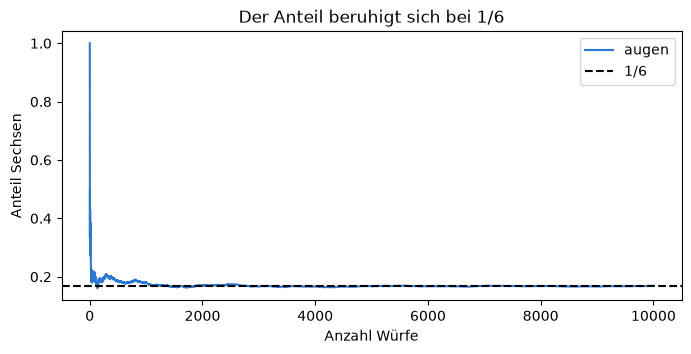

In [49]:
rng = np.random.default_rng(7)
augen = pd.Series(rng.integers(1, 7, size=10000), index=range(1, 10001), name="augen")

anteil_sechs = (augen == 6).expanding().mean()
print(anteil_sechs.loc[[10, 100, 10000]].round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
anteil_sechs.plot(ax=ax, color=BLAU)
ax.axhline(1 / 6, color="black", linestyle="--", label="1/6")
ax.set_xlabel("Anzahl Würfe")
ax.set_ylabel("Anteil Sechsen")
ax.set_title("Der Anteil beruhigt sich bei 1/6")
ax.legend()
plt.show()

Nach 10 Würfen 30 % Sechsen, nach 100 Würfen 20 %, nach 1000 Würfen 18 %. Der Anteil schwankt am Anfang stark und nähert sich dann 1/6 ≈ 16,7 %.

`rng.integers(1, 7)` erzeugt Zahlen von 1 bis 6, die 7 gehört nicht dazu (wie bei `range`).

## 10 – Ausblick: `rolling()`

`rolling(50).mean()` ist ein **gleitendes Fenster** über immer nur die letzten 50 Würfe. Es beruhigt sich nicht, denn 50 Würfe sind immer nur 50 Würfe. Das Gesetz der großen Zahlen gilt für den **Gesamtanteil**.

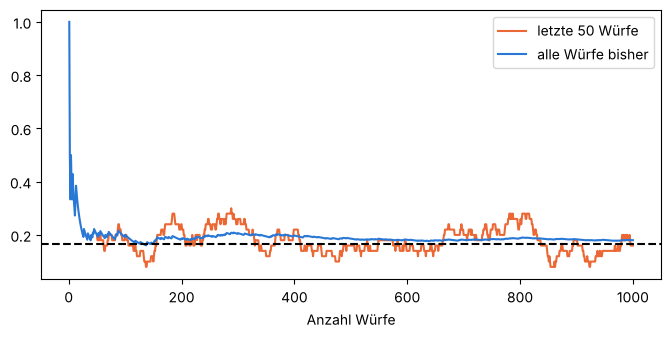

In [ ]:
fenster = (augen == 6).rolling(50).mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
fenster.plot(ax=ax, color=ORANGE, label="letzte 50 Würfe")
anteil_sechs.plot(ax=ax, color=BLAU, label="alle Würfe bisher")
ax.axhline(1 / 6, color="black", linestyle="--")
ax.set_xlabel("Anzahl Würfe")
ax.legend()
plt.show()

### Übung 4

Wirf eine Münze 1000-mal mit `rng = np.random.default_rng(3)` und `rng.integers(0, 2, size=1000)` (1 = Kopf).

- **a)** Berechne den laufenden Anteil Kopf mit `expanding()`. Wie hoch ist er nach 10, 100 und 1000 Würfen?
- **b)** Zeichne den Verlauf mit einer Linie bei 0,5.
- **c)** Ab wann bleibt der Anteil zwischen 0,45 und 0,55? *Hinweis: Suche den letzten Wurf, bei dem er noch außerhalb lag.*

In [57]:
# a) 1 = Kopf
rng = np.random.default_rng(5)
muenze_1000 = pd.Series(rng.integers(0, 2, size=10000), index=range(1, 10001))
anteil_kopf = (muenze_1000 == 1).expanding().mean()
print(anteil_kopf.loc[[10, 100, 10000]].round(3))


10       0.600
100      0.460
10000    0.501
dtype: float64


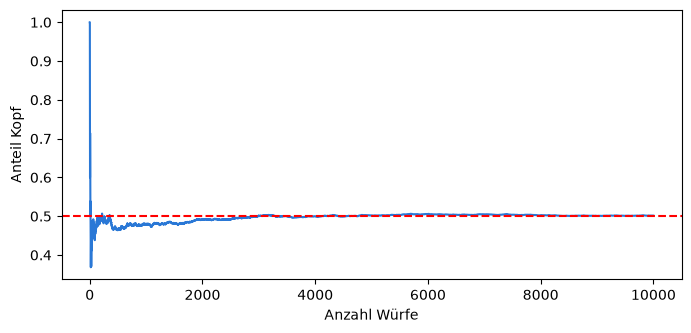

In [58]:
# b)
fig, ax = plt.subplots(figsize=(8, 3.5))
anteil_kopf.plot(ax=ax, color=BLAU)
ax.axhline(0.5, color="red", linestyle="--")
ax.set_xlabel("Anzahl Würfe")
ax.set_ylabel("Anteil Kopf")
plt.show()

In [59]:
# c)
ausserhalb = ~anteil_kopf.between(0.45, 0.55)
letzter = ausserhalb[ausserhalb].index.max()
print(letzter)

90


---
# Block E – „Mindestens einmal"

## 11 – `any` und `all` mit `axis=1`

> **Herr Bauchgefühl:** „Bei 4 Würfen kommt die 6 mit 4 · 1/6 ≈ 67 %. Bei 6 Würfen sogar mit 100 %!"

Wir simulieren 100 000 Versuche mit je 4 Würfen. **Jede Zeile ist ein Versuch, jede Spalte eine Stufe im Baum.**

- `any(axis=1)`: In der Zeile ist **mindestens ein** `True`.
- `all(axis=1)`: In der Zeile ist **jeder** Wert `True`.

In [ ]:
rng = np.random.default_rng(4)
vier = pd.DataFrame(rng.integers(1, 7, size=(100_000, 4)), columns=["w1", "w2", "w3", "w4"])
print(vier.head())
print()

mind_eine_sechs = (vier == 6).any(axis=1)
keine_sechs = (vier != 6).all(axis=1)

print("P(mindestens eine 6) simuliert:", round(mind_eine_sechs.mean(), 3))
print("P(keine 6) simuliert:          ", round(keine_sechs.mean(), 3))
print("Formel 1 - (5/6)^4:            ", round(1 - (5 / 6) ** 4, 3))

   w1  w2  w3  w4
0   5   6   6   4
1   6   6   6   1
2   3   4   2   3
3   4   5   4   2
4   5   6   2   4

P(mindestens eine 6) simuliert: 0.519
P(keine 6) simuliert:           0.481
Formel 1 - (5/6)^4:             0.518


<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="120">

Rund 52 %, nicht 67 %. „Mindestens einmal" ist das **Gegenereignis** von „keinmal", deshalb ergänzen sich die beiden Werte zu 1. Dass die Simulation etwas anders liegt als die Formel, ist kein Fehler: Das ist der Zufall, siehe Block D.

### Übung 5

Übung 11 vom Vormittag. Ein Server fällt an jedem Arbeitstag mit 5 % Wahrscheinlichkeit aus, unabhängig von den anderen Tagen. Simuliere 100 000 Wochen mit `rng = np.random.default_rng(5)` und `rng.random((100_000, 5)) < 0.05`.

- **a)** Wie groß ist P(mindestens ein Ausfall in 5 Tagen)? Vergleiche mit 0,226.
- **b)** Wie groß ist P(kein Ausfall)?
- **c)** Wie groß ist P(mindestens ein Ausfall in 30 Tagen)? Vergleiche mit 0,785.

In [67]:
# a) rng.random() = Zahlen zwischen 0 und 1
rng = np.random.default_rng(42)
server = pd.DataFrame(rng.random((100_000, 5)) < 0.05, columns=["Mo", "Di", "Mi", "Do", "Fr"])
server.head(10)
# print(server.any(axis=1).mean())


,Mo,Di,Mi,Do,Fr
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,True,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


In [68]:
# b) 0,95 ^ 5 = 0,774
print((~server).all(axis=1).mean())
print(((~server) == (1 - server)).mean())


0.77404
Mo    1.0
Di    1.0
Mi    1.0
Do    1.0
Fr    1.0
dtype: float64


In [ ]:
# c) 30 Spalten statt 5
server30 = pd.DataFrame(rng.random((100_000, 30)) < 0.05)
print(server30.any(axis=1).mean(), round(1 - 0.95 ** 30, 3))

0.7842 0.785


---
# Block F – Der Serien-Detektor und weitere Übungen

- **Abschnitt 12 und 13:** der Serien-Detektor (neu: `shift()` und `cumsum()`)
- **Übung 6:** eure Reißzwecken-Daten (zu Block C)
- **Übung 7:** Gegenprobe zum Vormittag (zu Block A und B)
- **Übung 8:** Echt oder erfunden? (zu Abschnitt 12 und 13)

## 12 – Wie lang ist die längste Serie?

<img src="png%20Dateien/der_ausreisser.png" alt="Der Ausreißer" width="110">

**Der Ausreißer:** „Fünfmal Kopf hintereinander ist nicht verdächtig. Verdächtig ist, wenn so etwas nie vorkommt."

Für die längste Serie brauchen wir zwei neue Werkzeuge:

- `shift()` verschiebt eine Spalte um eine Zeile nach unten. So steht der vorherige Wurf neben dem aktuellen.
- `s != s.shift()` ist `True`, wenn sich der Wurf **ändert**. `cumsum()` darauf zählt die Wechsel mit, und jede Serie bekommt so ihre eigene Gruppennummer.

In [ ]:
s = pd.Series(list("KZZKKKKKZZ"))
pd.DataFrame({
    "wurf": s,
    "vorher": s.shift(),
    "wechsel": s != s.shift(),
    "gruppe": (s != s.shift()).cumsum(),
})

,wurf,vorher,wechsel,gruppe
0,K,NaN,True,1
1,Z,K,True,2
2,Z,Z,False,2
3,K,Z,True,3
4,K,K,False,3
5,K,K,False,3
6,K,K,False,3
7,K,K,False,3
8,Z,K,True,4
9,Z,Z,False,4


Gruppe 3 hat 5 Zeilen: fünfmal Kopf. Jetzt zählen wir mit `groupby` die Länge jeder Gruppe und nehmen das Maximum. Das packen wir in eine Funktion:

In [ ]:
def laengste_serie(folge):
    s = pd.Series(list(folge))
    gruppe = (s != s.shift()).cumsum()
    return s.groupby(gruppe).size().max()

echt = "KZZKKKKKZZKZZZKZKKZZZZKZKKKZKZ"   # Beispiel aus dem Skript
fake = "KZKZZKZKKZKZZKZKZKKZKZZKZKZKZK"

print("echt:", laengste_serie(echt))
print("fake:", laengste_serie(fake))

echt: 5
fake: 2


## 13 – Wie lang sind Serien in echten Zufallsfolgen?

Wir simulieren 2000 echte Folgen mit je 30 Würfen und messen bei jeder die längste Serie. `apply(..., axis=1)` wendet die Funktion auf jede Zeile an. Das kommt an Tag 3 ausführlich, hier benutzen wir es nur. Die Zelle braucht ein paar Sekunden.

In [ ]:
rng = np.random.default_rng(12)
folgen = pd.DataFrame(rng.integers(0, 2, size=(2000, 30))).replace({0: "K", 1: "Z"})
laengen = folgen.apply(lambda zeile: laengste_serie("".join(zeile)), axis=1)

print("P(längste Serie mindestens 4):", round((laengen >= 4).mean(), 2))
print("P(längste Serie mindestens 5):", round((laengen >= 5).mean(), 2))
laengen.value_counts().sort_index()

P(längste Serie mindestens 4): 0.89
P(längste Serie mindestens 5): 0.62


2       4
3     209
4     539
5     557
6     339
7     168
8      93
9      44
10     33
11      7
12      4
13      2
15      1
Name: count, dtype: int64

In rund 9 von 10 echten Folgen gibt es eine Serie von mindestens 4, in rund 6 von 10 sogar von mindestens 5. Wer sich eine Folge ausdenkt, wechselt meistens zu oft. Eine längste Serie von 2 ist bei 30 Würfen sehr verdächtig.

### Übung 6 – Eure Reißzwecken (zu Block C)

Übung 7 vom Vormittag. Ersetze die Platzhalter durch eure Daten von der Tafel.

- **a)** Berechne für jede Person die Anzahl „Seite" und den Anteil „Rücken".
- **b)** Berechne den Gesamtanteil „Rücken" für den ganzen Kurs. Achtung: Gesamtsumme durch Gesamtsumme, nicht der Mittelwert der Anteile.
- **c)** Wie stark schwanken die einzelnen Personen? Was sagt das über 20 Würfe aus?
- **d)** Simuliere 1000 Würfe mit `weights` aus eurem Gesamtanteil.

In [ ]:
kurs = pd.DataFrame({
    "person": ["Anna", "Ben", "Cem", "Dana", "Eli"],   # erfundene Platzhalter, durch eure Daten ersetzen
    "ruecken": [13, 9, 14, 11, 12],
    "wuerfe": 20,
})
kurs

,person,ruecken,wuerfe
0,Anna,13,20
1,Ben,9,20
2,Cem,14,20
3,Dana,11,20
4,Eli,12,20


In [ ]:
# a)


In [ ]:
# b)


In [ ]:
# c)


In [ ]:
# d)


### Übung 7 – Gegenprobe zum Vormittag (zu Block A und B)

- **a)** Übung 2c: Zwei Münzen. Wie groß ist P(genau ein Kopf) und P(mindestens ein Kopf)? Nutze `muenzen` aus Abschnitt 5.
- **b)** Übung 5b: T = Tee, V = Vormittag. Wie viele Personen gehören zu T ∩ V, T ∪ V und T̄? *Hinweis: `sum()` statt `mean()` liefert Anzahlen.*

In [ ]:
# a)


In [ ]:
# b)


### Übung 8 – Echt oder erfunden? (zu Abschnitt 12 und 13)

Übung 12 vom Vormittag. Jedes Team hat eine erfundene und eine echte Folge mit 30 Würfen aufgeschrieben. Trage eure Folgen als Text ein (nur K und Z).

- **a)** Bestimme mit `laengste_serie` die längste Serie jeder Folge.
- **b)** Welcher Anteil der simulierten Folgen (`laengen`) hat eine **so kurze oder kürzere** längste Serie wie eure erfundene Folge?
- **c)** Welche Folge ist echt? Begründe mit den Zahlen.

In [ ]:
team_folgen = {
    "Folge 1": "KZKZZKZKKZKZZKZKZKKZKZZKZKZKZK",   # Platzhalter: durch eure Folgen ersetzen
    "Folge 2": "KZZKKKKKZZKZZZKZKKZZZZKZKKKZKZ",
}

In [ ]:
# a)


In [ ]:
# b)


In [ ]:
# c)


---
## 14 – Zusammenfassung

| Aufgabe | Befehl |
|---|---|
| Ereignis als Maske | `umfrage["getraenk"] == "Kaffee"` |
| Wahrscheinlichkeit beim Auslosen | `maske.mean()`; Anzahl mit `maske.sum()` |
| und / oder / nicht | `(a) & (b)`, `(a) \| (b)`, `~a` (Klammern!) |
| mehrere Werte, Bereich | `isin([...])`, `between(von, bis)` (Grenzen inklusive) |
| Bedingung als Text | `df.query('spalte == "Wert" or andere > 50')` |
| Ergebnisraum | `links.merge(rechts, how="cross")` |
| zeilenweise rechnen | `sum(axis=1)`, `any(axis=1)`, `all(axis=1)` |
| Ziehen mit Zurücklegen | `sample(n=..., replace=True, random_state=...)` |
| ungleiche Chancen | `sample(..., weights=[...])` |
| laufender Anteil | `maske.expanding().mean()` |
| gleitendes Fenster | `rolling(50).mean()` |
| Vorzeile | `shift()` |
| Serien als Gruppen | `(s != s.shift()).cumsum()` |
| Zufallszahlen | `rng = np.random.default_rng(seed)`, `rng.integers(...)`, `rng.random(...)` |

**Merke:** Eine Simulation liefert ungefähr die Formelwerte. Je mehr Wiederholungen, desto näher, das ist das Gesetz der großen Zahlen.

---
*Material erstellt von Julia Brutskaya*